# Завдання для студентів

Виконайте завдання нижче самостійно. Після кожного завдання додайте короткий висновок у Markdown-комірці: **що саме було виявлено і чому це важливо**.

## 0. Підготовка середовища

Спочатку імпортуємо бібліотеки та перевіримо версію pandas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 2.2.3
numpy: 2.1.3


## 1. Створення навчального набору даних

Щоб ноутбук був автономним і запускався у Colab без зовнішніх файлів, згенеруємо невеликий набір даних про клієнтів інтернет-магазину. У ньому навмисно є пропуски, дублікати та неакуратні текстові значення.

In [2]:
rng = np.random.default_rng(42)

n = 120
cities = np.array(["Kyiv", "Lviv", "Odesa", "Dnipro", "Kharkiv"])
segments = np.array(["basic", "standard", "premium"])

customers = pd.DataFrame({
    "customer_id": np.arange(1001, 1001 + n),
    "age": rng.integers(18, 70, size=n),
    "city": rng.choice(cities, size=n, p=[0.30, 0.20, 0.18, 0.16, 0.16]),
    "segment": rng.choice(segments, size=n, p=[0.45, 0.40, 0.15]),
    "signup_date": pd.Timestamp("2022-01-01") + pd.to_timedelta(
        rng.integers(0, 1600, size=n), unit="D"
    ),
    "orders": rng.poisson(7, size=n),
    "spend": np.round(rng.gamma(shape=2.3, scale=280, size=n), 2),
    "churn": rng.choice([0, 1], size=n, p=[0.78, 0.22]),
})

# Навмисно додаємо проблеми якості даних
customers.loc[[5, 18, 44], "age"] = np.nan
customers.loc[[9, 27, 78, 101], "spend"] = np.nan
customers.loc[12, "city"] = " kyiv "
customers.loc[31, "city"] = "LVIV"
customers.loc[66, "segment"] = None
customers.loc[88, "spend"] = -150.0

# Додаємо два дублікати рядків
customers = pd.concat([customers, customers.iloc[[3, 15]]], ignore_index=True)

customers.to_csv("customers_eda.csv", index=False)
print("Файл створено: customers_eda.csv")
print("Розмір:", customers.shape)
customers.head()

Файл створено: customers_eda.csv
Розмір: (122, 8)


,customer_id,age,city,segment,signup_date,orders,spend,churn
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0


## 2. Завантаження даних та первинна перевірка

Завантажимо CSV так, як це робиться у реальному проєкті.

In [3]:
df = pd.read_csv(
    "customers_eda.csv",
    parse_dates=["signup_date"],
)

df.head()

,customer_id,age,city,segment,signup_date,orders,spend,churn
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0


In [4]:
df.shape

(122, 8)

In [5]:
df.columns

Index(['customer_id', 'age', 'city', 'segment', 'signup_date', 'orders',
       'spend', 'churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  122 non-null    int64         
 1   age          119 non-null    float64       
 2   city         122 non-null    object        
 3   segment      121 non-null    object        
 4   signup_date  122 non-null    datetime64[ns]
 5   orders       122 non-null    int64         
 6   spend        118 non-null    float64       
 7   churn        122 non-null    int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(2)
memory usage: 7.8+ KB


In [7]:
df.describe()

,customer_id,age,signup_date,orders,spend,churn
count,122.000000,119.000000,122,122.000000,118.000000,122.000000
mean,1059.672131,44.512605,2024-04-23 11:00:59.016393472,6.959016,672.393814,0.278689
min,1001.000000,18.000000,2022-01-13 00:00:00,1.000000,-150.000000,0.000000
25%,1029.250000,33.000000,2023-05-01 06:00:00,5.000000,341.800000,0.000000
50%,1059.500000,44.000000,2024-05-06 12:00:00,7.000000,621.640000,0.000000
75%,1089.750000,57.000000,2025-03-27 06:00:00,8.000000,901.750000,1.000000
max,1120.000000,68.000000,2026-05-14 00:00:00,14.000000,2046.770000,1.000000
std,35.100668,14.038606,NaN,2.556462,445.379828,0.450203


## Завдання 1. Первинний аудит даних
1. Визначте розмір `df`.
2. Виведіть типи всіх стовпців.
3. Порахуйте кількість унікальних значень у кожному стовпці.
4. Визначте частку пропусків.
5. Назвіть щонайменше три потенційні проблеми якості даних.

In [8]:
# 1.
print("Розмір DataFrame:", df.shape)

# 2.
print("\nТипи стовпців:")
print(df.dtypes)

# 3.
print("\nКількість унікальних значень:")
print(df.nunique())

# 4.
print("\nЧастка пропусків:")
print(df.isna().mean())

# 5.
print("\nКількість пропусків:")
print(df.isna().sum())

Розмір DataFrame: (122, 8)

Типи стовпців:
customer_id             int64
age                   float64
city                   object
segment                object
signup_date    datetime64[ns]
orders                  int64
spend                 float64
churn                   int64
dtype: object

Кількість унікальних значень:
customer_id    120
age             45
city             7
segment          3
signup_date    117
orders          14
spend          116
churn            2
dtype: int64

Частка пропусків:
customer_id    0.000000
age            0.024590
city           0.000000
segment        0.008197
signup_date    0.000000
orders         0.000000
spend          0.032787
churn          0.000000
dtype: float64

Кількість пропусків:
customer_id    0
age            3
city           0
segment        1
signup_date    0
orders         0
spend          4
churn          0
dtype: int64


### Висновок до завдання 1

Під час первинного аудиту було визначено розмір набору даних, типи стовпців, кількість унікальних значень та частку пропусків. Було виявлено пропуски в стовпцях `age`, `spend` та `segment`, а також наявність неакуратних текстових значень і дублікатів. Це важливо, оскільки такі проблеми можуть впливати на точність подальшого аналізу та статистичних розрахунків.

## Завдання 2. Фільтрація
Створіть DataFrame `task2`, який містить клієнтів:
- віком від 30 до 50 років;
- із сегменту `premium` або `standard`;
- з витратами понад 600;
- лише зі стовпцями `customer_id`, `age`, `city`, `segment`, `spend`.

Відсортуйте результат за `spend` за спаданням.

In [9]:
task2 = df[
    (df["age"].between(30, 50)) &
    (df["segment"].isin(["premium", "standard"])) &
    (df["spend"] > 600)
][["customer_id", "age", "city", "segment", "spend"]].sort_values(
    by="spend",
    ascending=False
)

print("Результат фільтрації:")
print(task2)

Результат фільтрації:
     customer_id   age     city   segment    spend
29          1030  41.0    Odesa  standard  1651.09
84          1085  50.0     Lviv   premium  1386.54
118         1119  30.0  Kharkiv  standard  1243.22
21          1022  37.0     Lviv   premium  1162.84
75          1076  42.0     Kyiv  standard   997.35
43          1044  36.0  Kharkiv   premium   963.23
76          1077  35.0  Kharkiv  standard   898.33
64          1065  39.0     Kyiv  standard   870.96
30          1031  41.0     Kyiv  standard   851.50
65          1066  34.0     Lviv   premium   848.28
115         1116  47.0     Kyiv   premium   795.16
112         1113  46.0     Kyiv   premium   770.63
20          1021  44.0    Odesa  standard   711.92
81          1082  40.0     Lviv  standard   704.74
38          1039  32.0     Kyiv   premium   701.06
114         1115  44.0     Kyiv  standard   604.29


### Висновок до завдання 2

Було відібрано клієнтів віком від 30 до 50 років із сегментів `premium` або `standard`, які витратили понад 600. Результат відсортовано за витратами у порядку спадання. Така фільтрація дозволяє виділити клієнтів, які відповідають заданим критеріям для подальшого аналізу.

## Завдання 3. Очищення
На копії `df` виконайте:
1. видалення повних дублікатів;
2. очищення пробілів і регістру в `city`;
3. заміну від’ємних `spend` на пропуск;
4. підрахунок кількості пропусків після очищення;
5. поясніть, які пропуски ви б видаляли, а які — імпутували.

In [10]:
clean_df = df.copy()

# 1.
clean_df = clean_df.drop_duplicates()

# 2.
clean_df["city"] = clean_df["city"].str.strip().str.lower()

# 3.
clean_df.loc[clean_df["spend"] < 0, "spend"] = np.nan

# 4.
print("Кількість пропусків після очищення:")
print(clean_df.isna().sum())

print("\nРозмір після видалення дублікатів:", clean_df.shape)

Кількість пропусків після очищення:
customer_id    0
age            3
city           0
segment        1
signup_date    0
orders         0
spend          5
churn          0
dtype: int64

Розмір після видалення дублікатів: (120, 8)


### Висновок до завдання 3

Після очищення було видалено повні дублікати, нормалізовано написання міст та від'ємне значення `spend` замінено на пропуск. Пропуски в `age` та `spend` доцільно аналізувати перед видаленням: якщо таких записів небагато, їх можна видалити для конкретного розрахунку або імпутувати відповідним статистичним значенням. Пропуски в `segment` також можна імпутувати лише за наявності обґрунтованого правила, оскільки сегмент є категоріальною ознакою.

## Завдання 4. Групова аналітика
Для кожного `segment` обчисліть:
- кількість клієнтів;
- середню кількість замовлень;
- медіанні витрати;
- сумарні витрати;
- churn rate.

Відсортуйте сегменти за churn rate від найбільшого до найменшого.

In [11]:
segment_analysis = (
    clean_df
    .groupby("segment")
    .agg(
        customer_count=("customer_id", "count"),
        average_orders=("orders", "mean"),
        median_spend=("spend", "median"),
        total_spend=("spend", "sum"),
        churn_rate=("churn", "mean")
    )
    .sort_values("churn_rate", ascending=False)
)

segment_analysis["churn_rate"] = segment_analysis["churn_rate"] * 100

print(segment_analysis)

          customer_count  average_orders  median_spend  total_spend  \
segment                                                               
standard              43        7.000000       503.860     27178.88   
basic                 58        6.793103       668.135     37335.78   
premium               18        7.388889       738.405     12931.55   

          churn_rate  
segment               
standard   32.558140  
basic      24.137931  
premium    22.222222  


### Висновок до завдання 4

За допомогою групування за `segment` було отримано кількість клієнтів, середню кількість замовлень, медіанні та сумарні витрати, а також churn rate для кожного сегмента. Сортування за churn rate дозволяє порівняти сегменти за часткою клієнтів, які припинили користуватися сервісом.

## Завдання 5. Ознаки на основі дат
Створіть:
- `signup_year`;
- `signup_quarter`;
- `tenure_days` станом на 07.09.2026.

Після цього визначте, у якому році зареєструвалося найбільше клієнтів.

In [13]:
parse_dates=["signup_date"]

clean_df["signup_year"] = clean_df["signup_date"].dt.year
clean_df["signup_quarter"] = clean_df["signup_date"].dt.quarter

reference_date = pd.Timestamp("2026-09-07")

clean_df["tenure_days"] = (
    reference_date - clean_df["signup_date"]
).dt.days

print("Перші рядки з новими ознаками:")
print(
    clean_df[
        ["customer_id", "signup_date", "signup_year",
         "signup_quarter", "tenure_days"]
    ].head()
)

signup_by_year = clean_df["signup_year"].value_counts()

most_common_year = signup_by_year.idxmax()
most_common_year_count = signup_by_year.max()

print("\nКількість реєстрацій за роками:")
print(signup_by_year.sort_index())

print(
    f"\nНайбільше клієнтів зареєструвалося у "
    f"{most_common_year} році: {most_common_year_count}"
)

Перші рядки з новими ознаками:
   customer_id signup_date  signup_year  signup_quarter  tenure_days
0         1001  2024-09-13         2024               3          724
1         1002  2025-05-31         2025               2          464
2         1003  2025-03-28         2025               1          528
3         1004  2022-08-04         2022               3         1495
4         1005  2025-08-14         2025               3          389

Кількість реєстрацій за роками:
signup_year
2022    22
2023    21
2024    37
2025    27
2026    13
Name: count, dtype: int64

Найбільше клієнтів зареєструвалося у 2024 році: 37


### Висновок до завдання 5

На основі `signup_date` було створено рік реєстрації, квартал реєстрації та тривалість користування сервісом у днях станом на 07.09.2026. Аналіз кількості реєстрацій за роками дозволяє визначити період, у якому було залучено найбільше клієнтів. Ознака `tenure_days` може бути використана для подальшого аналізу зв'язку між тривалістю користування сервісом та поведінкою клієнтів.

## Завдання 6. Об’єднання таблиць
Створіть окрему таблицю `segment_info` з полями:
- `segment`;
- `discount_rate`;
- `support_level`.

Об’єднайте її з очищеним набором через `merge`. Обов’язково використайте `validate` і поясніть, який тип зв’язку очікується.

In [14]:
segment_info = pd.DataFrame({
    "segment": ["basic", "standard", "premium"],
    "discount_rate": [0.02, 0.05, 0.10],
    "support_level": ["standard", "priority", "premium"]
})

print("Таблиця segment_info:")
print(segment_info)

merged_df = clean_df.merge(
    segment_info,
    on="segment",
    how="left",
    validate="many_to_one"
)

print("\nРезультат об'єднання:")
print(merged_df.head())

print("\nРозмір після merge:", merged_df.shape)

Таблиця segment_info:
    segment  discount_rate support_level
0     basic           0.02      standard
1  standard           0.05      priority
2   premium           0.10       premium

Результат об'єднання:
   customer_id   age    city   segment signup_date  orders    spend  churn  \
0         1001  22.0   odesa   premium  2024-09-13       4   347.14      0   
1         1002  58.0    lviv   premium  2025-05-31       9   706.18      0   
2         1003  52.0   odesa  standard  2025-03-28      11  1164.91      0   
3         1004  40.0  dnipro     basic  2022-08-04       7    77.99      0   
4         1005  40.0   odesa  standard  2025-08-14       8   574.75      0   

   signup_year  signup_quarter  tenure_days  discount_rate support_level  
0         2024               3          724           0.10       premium  
1         2025               2          464           0.10       premium  
2         2025               1          528           0.05      priority  
3         2022        

### Висновок до завдання 6

Було створено таблицю `segment_info` з додатковою інформацією про кожен сегмент та об'єднано її з очищеним набором даних за полем `segment`.

Для `validate` використано `many_to_one`, оскільки в `clean_df` одному сегменту відповідає багато клієнтів, а в `segment_info` кожен сегмент зустрічається лише один раз. Тобто очікується зв'язок «багато до одного».

## Завдання 7. Pivot table
Побудуйте `pivot_table`, де:
- рядки — `city`;
- стовпці — `segment`;
- значення — медіана `spend`.

Визначте комбінацію місто–сегмент із найбільшою медіаною витрат.

In [15]:
pivot_spend = pd.pivot_table(
    clean_df,
    index="city",
    columns="segment",
    values="spend",
    aggfunc="median"
)

print("Pivot table — медіана spend:")
print(pivot_spend)

max_city, max_segment = pivot_spend.stack().idxmax()
max_value = pivot_spend.stack().max()

print(
    f"\nНайбільша медіана витрат: "
    f"{max_value:.2f}"
)
print(
    f"Комбінація: місто — {max_city}, сегмент — {max_segment}"
)

Pivot table — медіана spend:
segment   basic   premium  standard
city                               
dnipro   703.23  1254.480   456.840
kharkiv  533.90   762.485   767.885
kyiv     663.68   701.060   727.895
lviv     679.78   777.230   425.100
odesa    672.59   639.000   489.180

Найбільша медіана витрат: 1254.48
Комбінація: місто — dnipro, сегмент — premium


### Висновок до завдання 7

За допомогою `pivot_table` було розраховано медіанне значення витрат для кожної комбінації міста та сегмента. Найбільша медіана витрат відповідає комбінації, яку було визначено за допомогою `idxmax()`.

## Завдання 8. Візуалізація
Побудуйте щонайменше три різні графіки:
1. розподіл `age`;
2. boxplot `spend` за сегментами;
3. churn rate за містами.

Для кожного графіка напишіть 1–2 речення інтерпретації.

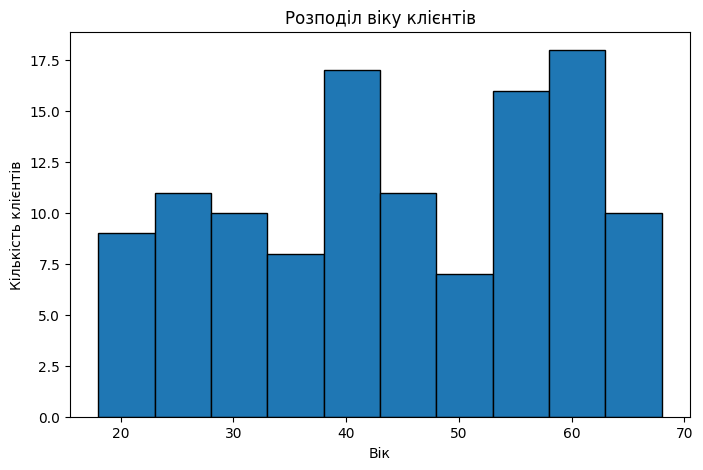

In [18]:
#8.1. Розподіл age

plt.figure(figsize=(8, 5))
plt.hist(clean_df["age"].dropna(), bins=10, edgecolor="black")
plt.title("Розподіл віку клієнтів")
plt.xlabel("Вік")
plt.ylabel("Кількість клієнтів")
plt.show()


### Інтерпретація

Гістограма показує розподіл клієнтів за віком. Найбільше спостережень зосереджено у вікових групах, де стовпці мають найбільшу висоту.

<Figure size 800x500 with 0 Axes>

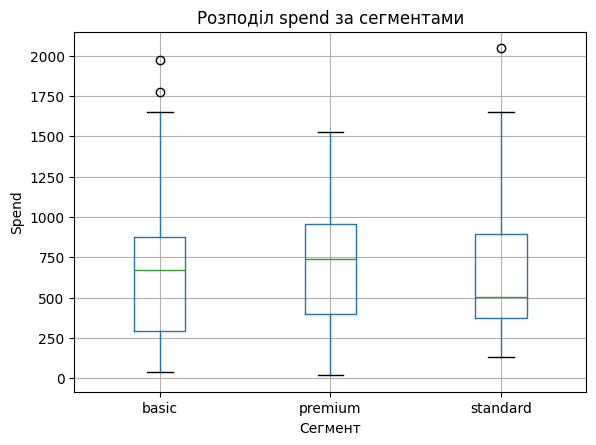

In [19]:
## 8.2. Boxplot витрат за сегментами

plt.figure(figsize=(8, 5))
clean_df.boxplot(
    column="spend",
    by="segment"
)
plt.title("Розподіл spend за сегментами")
plt.suptitle("")
plt.xlabel("Сегмент")
plt.ylabel("Spend")
plt.show()

### Інтерпретація

Boxplot дозволяє порівняти медіану, розкид витрат та потенційні викиди між сегментами. Відмінності між положенням медіан показують, що клієнти різних сегментів мають різний рівень витрат.

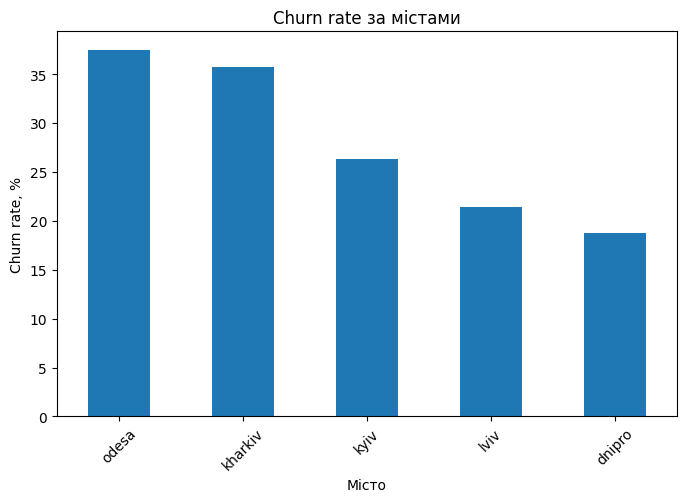

Churn rate за містами:
city
odesa      37.500000
kharkiv    35.714286
kyiv       26.315789
lviv       21.428571
dnipro     18.750000
Name: churn, dtype: float64


In [20]:
## 8.3. Churn rate за містами

churn_by_city = (
    clean_df
    .groupby("city")["churn"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

plt.figure(figsize=(8, 5))
churn_by_city.plot(kind="bar")
plt.title("Churn rate за містами")
plt.xlabel("Місто")
plt.ylabel("Churn rate, %")
plt.xticks(rotation=45)
plt.show()

print("Churn rate за містами:")
print(churn_by_city)

### Інтерпретація

Графік показує частку клієнтів із `churn = 1` у кожному місті. Міста відрізняються за рівнем churn, що може бути корисним для подальшого аналізу причин відтоку клієнтів.

## Завдання 9. Викиди
За правилом IQR знайдіть потенційні викиди `spend`.

Далі порівняйте середнє та медіану `spend` до і після **тимчасового** виключення цих рядків. Не видаляйте викиди з фінального DataFrame автоматично. Поясніть, чому.

In [21]:
spend_clean = clean_df["spend"].dropna()

Q1 = spend_clean.quantile(0.25)
Q3 = spend_clean.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = clean_df[
    (clean_df["spend"] < lower_bound) |
    (clean_df["spend"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Нижня межа:", lower_bound)
print("Верхня межа:", upper_bound)

print("\nКількість потенційних викидів:", len(outliers))

print("\nПотенційні викиди:")
print(
    outliers[
        ["customer_id", "spend", "segment", "city"]
    ]
)

mean_before = clean_df["spend"].mean()
median_before = clean_df["spend"].median()

spend_without_outliers = clean_df.loc[
    ~clean_df.index.isin(outliers.index),
    "spend"
]

mean_after = spend_without_outliers.mean()
median_after = spend_without_outliers.median()

print("\nПорівняння:")
print(f"Середнє до:    {mean_before:.2f}")
print(f"Медіана до:    {median_before:.2f}")
print(f"Середнє після:  {mean_after:.2f}")
print(f"Медіана після:  {median_after:.2f}")


Q1: 348.085
Q3: 900.61
IQR: 552.5250000000001
Нижня межа: -480.70250000000016
Верхня межа: 1729.3975

Кількість потенційних викидів: 3

Потенційні викиди:
    customer_id    spend   segment   city
6          1007  1771.49     basic  odesa
34         1035  2046.77  standard   lviv
67         1068  1972.21     basic   kyiv

Порівняння:
Середнє до:    680.21
Медіана до:    623.25
Середнє після:  646.73
Медіана після:  612.16


### Висновок до завдання 9

За правилом IQR було визначено потенційні викиди у стовпці `spend`. Після їх тимчасового виключення було порівняно середнє та медіану витрат.

Викиди не видаляються автоматично з фінального DataFrame, оскільки вони можуть бути не помилками, а реальними клієнтами з дуже високими витратами. Перед видаленням необхідно перевірити причину появи таких значень та предметну область.

## Завдання 10. Підсумковий EDA
Підготуйте короткий аналітичний висновок за набором даних. Він має містити:
- розмір і структуру даних;
- проблеми якості;
- 3–5 ключових статистичних спостережень;
- щонайменше 2 візуальні спостереження;
- потенційні ознаки для ML-моделі прогнозування `churn`;
- ризики data leakage;
- план preprocessing перед моделюванням.

In [23]:
print("Розмір даних:", clean_df.shape)

print("\nКількість клієнтів за сегментами:")
print(clean_df["segment"].value_counts(dropna=False))

print("\nСередній вік:", clean_df["age"].mean())
print("Медіана spend:", clean_df["spend"].median())
print("Середній spend:", clean_df["spend"].mean())
print("Середня кількість orders:", clean_df["orders"].mean())
print("Загальний spend:", clean_df["spend"].sum())
print("Загальний churn rate:", clean_df["churn"].mean() * 100)

print("\nChurn rate за містами:")
print(churn_by_city)

print("\nChurn rate за сегментами:")
print(segment_analysis["churn_rate"])

print("\nКількість реєстрацій за роками:")
print(clean_df["signup_year"].value_counts().sort_index())

Розмір даних: (120, 11)

Кількість клієнтів за сегментами:
segment
basic       58
standard    43
premium     18
NaN          1
Name: count, dtype: int64

Середній вік: 44.43589743589744
Медіана spend: 623.25
Середній spend: 680.2084347826087
Середня кількість orders: 6.95
Загальний spend: 78223.97
Загальний churn rate: 27.500000000000004

Churn rate за містами:
city
odesa      37.500000
kharkiv    35.714286
kyiv       26.315789
lviv       21.428571
dnipro     18.750000
Name: churn, dtype: float64

Churn rate за сегментами:
segment
standard    32.558140
basic       24.137931
premium     22.222222
Name: churn_rate, dtype: float64

Кількість реєстрацій за роками:
signup_year
2022    22
2023    21
2024    37
2025    27
2026    13
Name: count, dtype: int64


### Підсумковий висновок

У результаті проведеного EDA було проаналізовано набір даних про клієнтів. Початковий набір містив 122 рядки та 8 стовпців. Після очищення даних і видалення дублікатів залишилося 120 рядків.

Під час перевірки якості даних було знайдено декілька проблем: пропущені значення у стовпцях `age`, `spend` та `segment`, різний формат написання назв міст, від'ємне значення витрат та дублікати рядків. Ці проблеми були враховані під час очищення даних.

Під час аналізу було визначено середній вік клієнтів, середні витрати, кількість замовлень та рівень відтоку клієнтів. Також було видно, що різні сегменти клієнтів мають різний рівень витрат і кількість замовлень. За допомогою групування можна порівнювати сегменти та міста між собою за різними показниками.

Побудовані графіки допомогли краще побачити розподіл клієнтів за віком, різницю у витратах між сегментами та рівень відтоку за містами. Boxplot також показав наявність потенційних викидів у значеннях `spend`.

Для майбутньої моделі прогнозування `churn` можна використовувати такі ознаки, як `age`, `city`, `segment`, `orders`, `spend`, `signup_year`, `signup_quarter` та `tenure_days`. Категоріальні дані перед використанням у моделі потрібно закодувати.

Також потрібно враховувати ризик data leakage. Не можна використовувати дані, які стали відомі вже після того, як потрібно було зробити прогноз, або дані, які прямо містять інформацію про майбутній відтік клієнта.

Перед побудовою ML-моделі потрібно обробити пропуски та некоректні значення, підготувати категоріальні ознаки, за потреби масштабувати числові дані та розділити набір на навчальну і тестову частини. Усі параметри обробки даних потрібно визначати на навчальній частині, щоб не допустити витоку інформації.

Отже, під час роботи було виконано основні етапи розвідувального аналізу даних: перевірку, очищення, об'єднання таблиць, групування, побудову зведених таблиць, візуалізацію та пошук викидів. Отриманий набір даних можна використовувати як підготовлений матеріал для подальшого аналізу та побудови моделі прогнозування відтоку клієнтів.
